# 🚀 StressLens — Comprehensive End-to-End Machine Learning Research & Production Notebook
**Project:** Student Stress Assessment & Lifestyle Analytics Platform  
**Author:** Senior Machine Learning Engineer & Data Scientist  
**Dataset:** Kaggle Student Lifestyle and Stress Prediction Dataset  

---

## 📌 Executive Overview & Workflow Pipeline
This notebook serves as the single authoritative ML research and production pipeline for **StressLens**. It covers the complete lifecycle of data science and machine learning:

1. **Dataset Loading & Schema Inspection**
2. **Comprehensive Exploratory Data Analysis (EDA)**
   - Target Analysis (`Stress_Level` class distribution & balance)
   - Numerical Univariate Distributions & Skewness Analysis
   - Outlier Inspection via Boxplots & IQR
   - Categorical Univariate Breakdown (`Student_Type`)
   - Correlation Matrix & Heatmap Analysis
   - Bivariate Target Analysis (Lifestyle Indicators vs Stress Level)
   - Categorical Crosstab & Stress Rate Breakdown
3. **Data Quality & Data Cleaning** (Missing values, duplicate detection, deduplication)
4. **Data Leakage Audit**
5. **Feature Engineering & Preprocessing Pipeline** (`ColumnTransformer`, Imputation, One-Hot Encoding, Scaling)
6. **Stratified Train / Test Partitioning** (80% Train / 20% Test)
7. **Candidate Model Training & 5-Fold Stratified Cross-Validation** (Logistic Regression, Decision Tree, Random Forest, Extra Trees, XGBoost)
8. **Hyperparameter Tuning** (`GridSearchCV`)
9. **Model Evaluation & Metric Comparison** (Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix, ROC Curve)
10. **Final Model Selection & Pipeline Serialization** (`stresslens_v1.0.0.joblib`)
11. **Explainable AI (SHAP Global & Local Feature Attribution)**

---
## 1. Dataset Loading & Schema Inspection
Load the raw dataset from `../data/StressLevelDataset.csv` and inspect data shape, column data types, memory footprint, and sample records.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Visual Aesthetics Configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

DATA_PATH = "../data/StressLevelDataset.csv"
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset Dimensions: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print("\n=== COLUMN TYPES & MEMORY INFO ===")
df_raw.info()

print("\n=== FIRST 5 ROWS ===")
df_raw.head()

Dataset Dimensions: 25500 rows × 9 columns

=== COLUMN TYPES & MEMORY INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 25500 entries, 0 to 25499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Student_Type        24248 non-null  str    
 1   Sleep_Hours         24167 non-null  float64
 2   Study_Hours         24223 non-null  float64
 3   Social_Media_Hours  24188 non-null  float64
 4   Attendance          24195 non-null  float64
 5   Exam_Pressure       24230 non-null  float64
 6   Family_Support      24209 non-null  float64
 7   Month               24186 non-null  float64
 8   Stress_Level        25500 non-null  int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 1.8 MB

=== FIRST 5 ROWS ===


,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
0,school,6.868702,1.711722,3.176942,NaN,8.0,7.0,2.0,1
1,school,8.519088,3.251084,3.880787,93.978465,6.0,4.0,3.0,1
2,college,4.498770,6.306885,2.936172,64.421253,7.0,1.0,12.0,1
3,school,8.591223,2.384922,5.222832,81.868960,2.0,7.0,7.0,0
4,college,5.329293,9.345179,7.815869,85.847982,5.0,6.0,10.0,1


In [2]:
print("=== LAST 5 ROWS ===")
df_raw.tail()

=== LAST 5 ROWS ===


,Student_Type,Sleep_Hours,Study_Hours,Social_Media_Hours,Attendance,Exam_Pressure,Family_Support,Month,Stress_Level
25495,college,7.803069,7.328193,2.018277,75.435607,5.0,1.0,12.0,0
25496,school,6.734607,2.680109,3.355559,63.387386,8.0,9.0,2.0,1
25497,college,7.701671,2.631250,2.948252,79.818930,4.0,3.0,4.0,1
25498,school,5.903426,3.450424,6.823894,96.680773,2.0,6.0,6.0,0
25499,college,7.419726,6.442748,3.356066,81.452460,9.0,5.0,6.0,1


---
## 2. Comprehensive Exploratory Data Analysis (EDA)

Exploratory Data Analysis is divided into 7 detailed subsections to thoroughly understand feature behavior, target distribution, outliers, correlations, and relationships between lifestyle indicators and student stress levels.

### 2.1 Target Variable Analysis (`Stress_Level`)
We analyze the distribution of the target binary variable `Stress_Level`:
- `0`: Low / Normal Stress
- `1`: High Stress

=== TARGET CLASS DISTRIBUTION ===
              Student Count  Proportion (%)
Stress_Level                               
0                     17853           70.01
1                      7647           29.99


/tmp/ipykernel_75847/1833595245.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])
/tmp/ipykernel_75847/1833595245.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Low/Normal (0)', 'High (1)'])


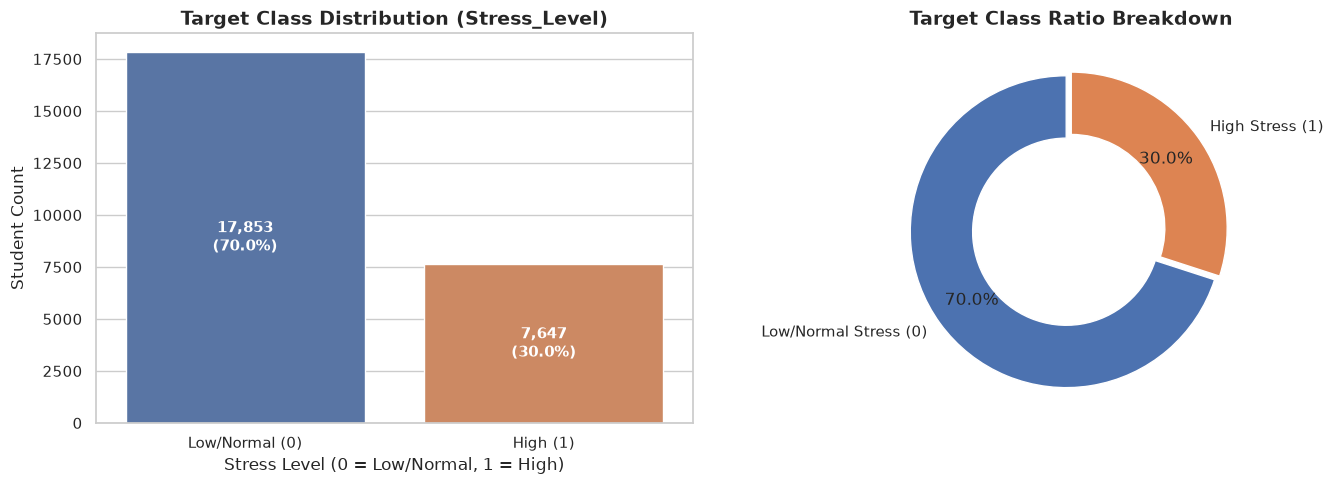

In [3]:
target_counts = df_raw['Stress_Level'].value_counts()
target_pcts = df_raw['Stress_Level'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Student Count': target_counts,
    'Proportion (%)': target_pcts.round(2)
})
print("=== TARGET CLASS DISTRIBUTION ===")
print(target_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar Chart
sns.barplot(x=target_counts.index, y=target_counts.values, ax=axes[0], palette=['#4C72B0', '#DD8452'])
axes[0].set_title('Target Class Distribution (Stress_Level)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Stress Level (0 = Low/Normal, 1 = High)')
axes[0].set_ylabel('Student Count')
axes[0].set_xticklabels(['Low/Normal (0)', 'High (1)'])

for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df_raw)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=11, color='white', fontweight='bold')

# Donut Chart
axes[1].pie(target_counts.values, labels=['Low/Normal Stress (0)', 'High Stress (1)'],
             autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'], startangle=90,
             explode=(0.04, 0), pctdistance=0.75, wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title('Target Class Ratio Breakdown', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 2.2 Numerical Features Descriptive Statistics & Skewness
Analyze continuous numerical indicators: `Sleep_Hours`, `Study_Hours`, `Social_Media_Hours`, `Attendance`, `Exam_Pressure`, `Family_Support`, and `Month`.

In [4]:
num_features = ['Sleep_Hours', 'Study_Hours', 'Social_Media_Hours', 'Attendance', 'Exam_Pressure', 'Family_Support', 'Month']

desc_stats = df_raw[num_features].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
desc_stats['skewness'] = df_raw[num_features].skew()

print("=== NUMERICAL DESCRIPTIVE STATISTICS & SKEWNESS ===")
desc_stats.round(3)

=== NUMERICAL DESCRIPTIVE STATISTICS & SKEWNESS ===


,mean,std,min,25%,50%,75%,max,skewness
Sleep_Hours,6.459,1.504,2.009,5.438,6.543,7.532,9.998,-0.232
Study_Hours,4.696,2.240,-1.433,3.078,4.538,6.136,22.444,0.555
Social_Media_Hours,3.556,1.902,0.000,2.152,3.501,4.864,9.962,0.254
Attendance,81.271,12.052,-5.000,73.739,81.943,90.107,120.000,-1.127
Exam_Pressure,5.370,2.394,1.000,4.000,5.000,7.000,10.000,0.005
Family_Support,5.798,2.232,1.000,4.000,6.000,7.000,10.000,-0.208
Month,6.501,3.455,1.000,3.000,6.000,10.000,12.000,0.005


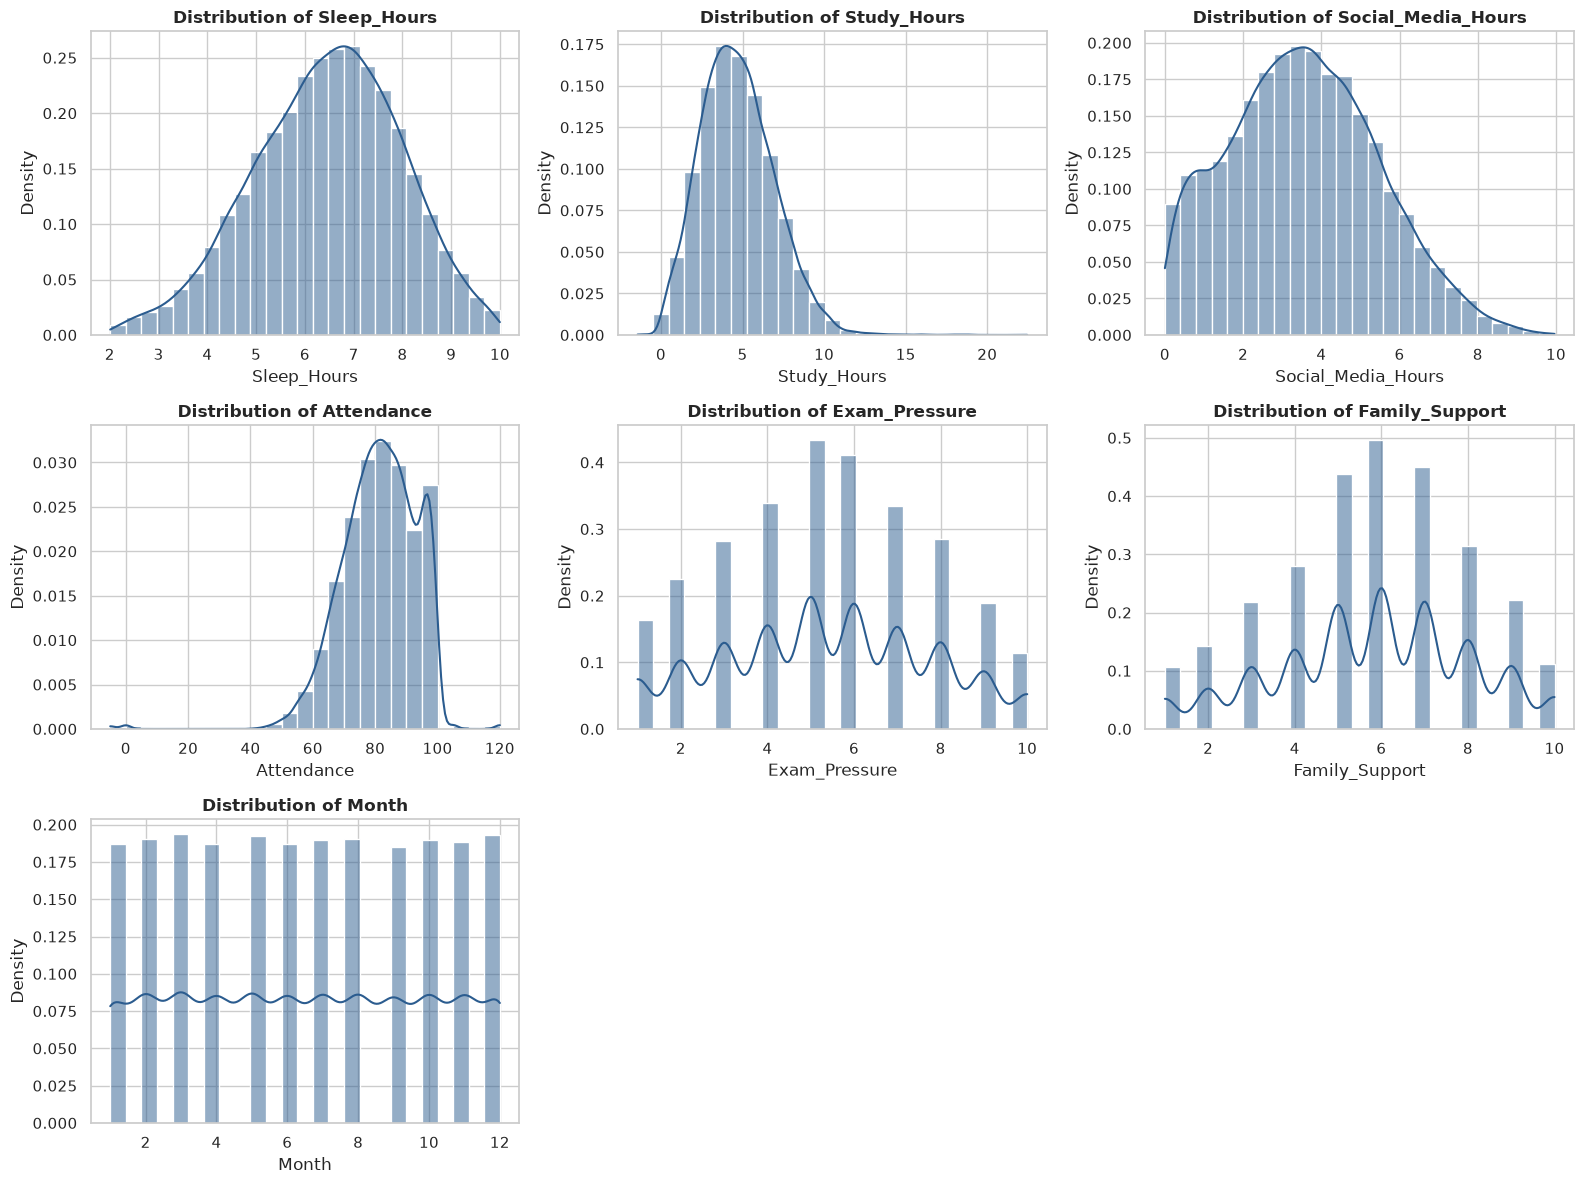

In [5]:
# Histograms & KDE Distributions
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.histplot(df_raw[col], kde=True, ax=axes[i], color='#2b5c8f', bins=25, stat="density")
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

for j in range(len(num_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 2.3 Outlier Inspection via Boxplots
Evaluate outlier presence and numerical spread for all continuous features.

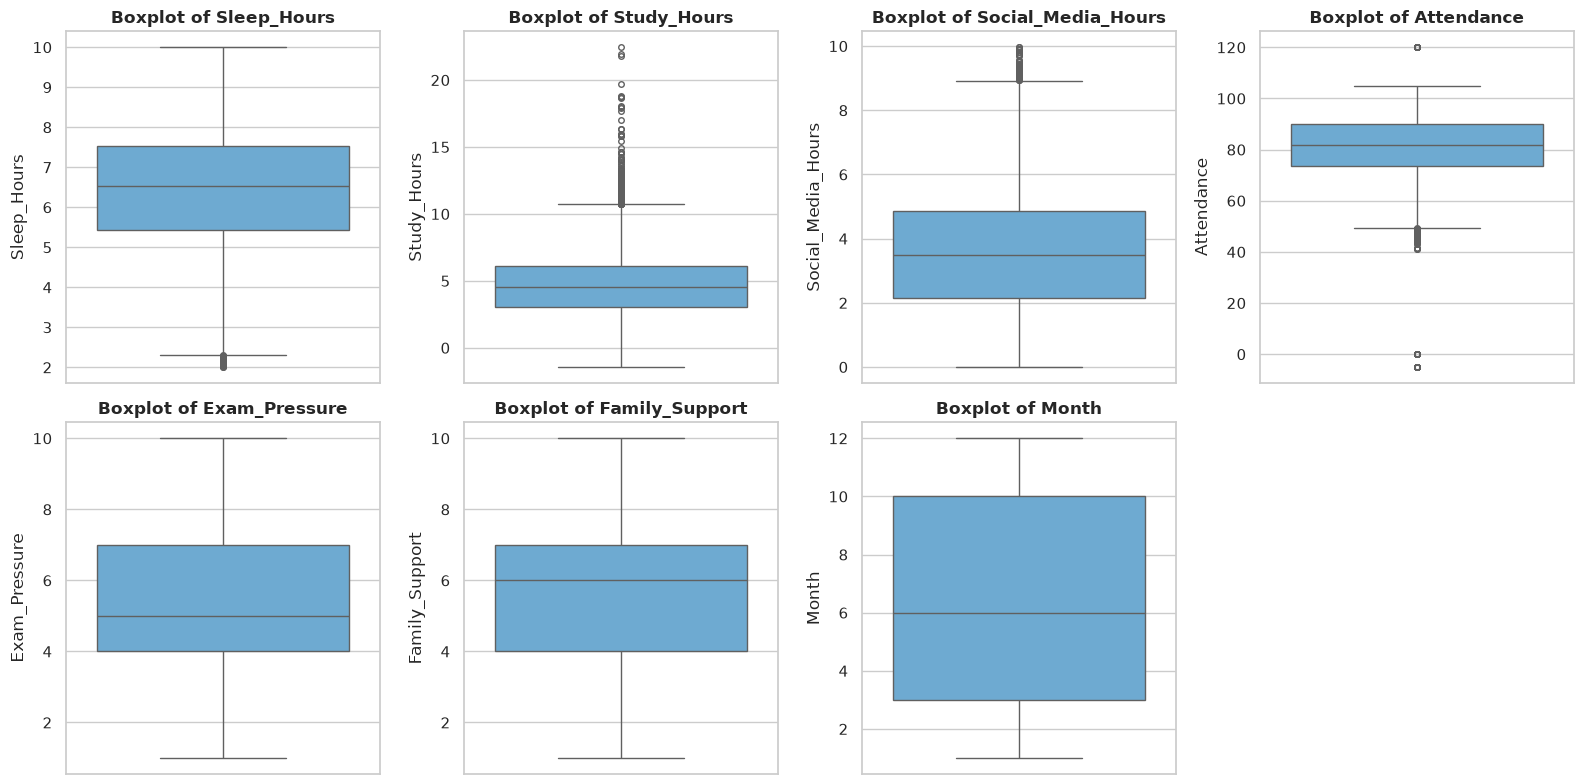

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(y=df_raw[col], ax=axes[i], color='#5DADE2', flierprops=dict(marker='o', color='red', markersize=4))
    axes[i].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel(col)

for j in range(len(num_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 2.4 Categorical Feature Breakdown (`Student_Type`)
Frequency analysis of the categorical variable `Student_Type`.

=== CATEGORICAL FEATURE SUMMARY (Student_Type) ===
                 Count  Proportion (%)
Student_Type                          
college          13391           52.51
school            6021           23.61
working_student   4836           18.96
NaN               1252            4.91


/tmp/ipykernel_75847/1887843490.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=cat_counts.index.astype(str), y=cat_counts.values, palette='Set2')


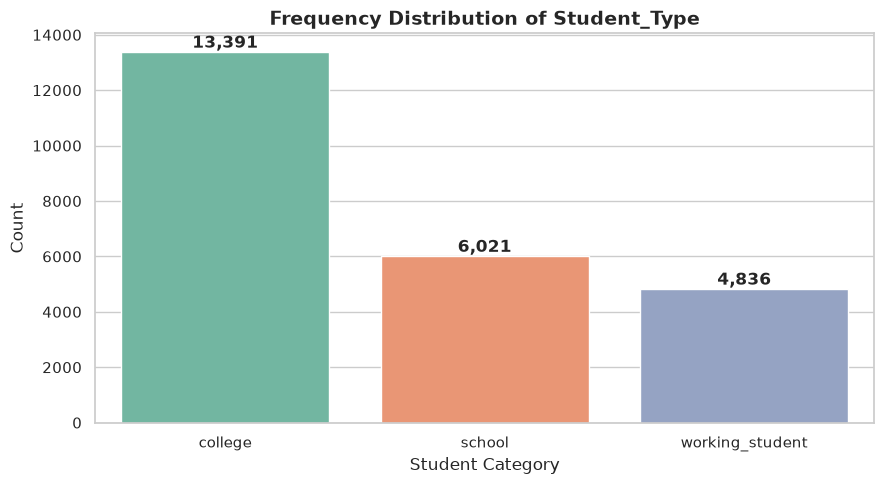

In [7]:
cat_counts = df_raw['Student_Type'].value_counts(dropna=False)
cat_pcts = df_raw['Student_Type'].value_counts(normalize=True, dropna=False) * 100

cat_summary = pd.DataFrame({'Count': cat_counts, 'Proportion (%)': cat_pcts.round(2)})
print("=== CATEGORICAL FEATURE SUMMARY (Student_Type) ===")
print(cat_summary)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=cat_counts.index.astype(str), y=cat_counts.values, palette='Set2')
plt.title('Frequency Distribution of Student_Type', fontsize=14, fontweight='bold')
plt.xlabel('Student Category')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 6), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

### 2.5 Feature Correlation Matrix & Heatmap Analysis
Examine linear relationships (Pearson correlation) between numerical indicators and the target variable.

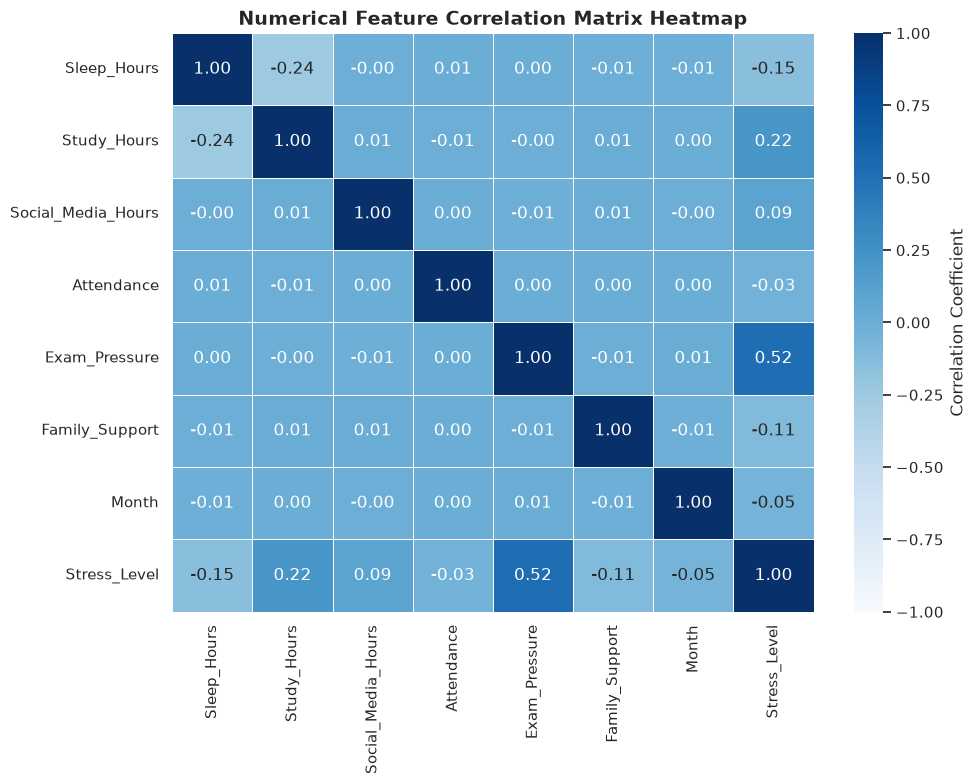

=== CORRELATION WITH TARGET (Stress_Level) ===
Stress_Level          1.0000
Exam_Pressure         0.5191
Study_Hours           0.2158
Social_Media_Hours    0.0900
Attendance           -0.0328
Month                -0.0499
Family_Support       -0.1075
Sleep_Hours          -0.1457
Name: Stress_Level, dtype: float64


In [8]:
plt.figure(figsize=(10, 8))
corr_matrix = df_raw[num_features + ['Stress_Level']].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient'})
plt.title("Numerical Feature Correlation Matrix Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("=== CORRELATION WITH TARGET (Stress_Level) ===")
print(corr_matrix['Stress_Level'].sort_values(ascending=False).round(4))

### 2.6 Bivariate Relationships: Lifestyle Indicators vs Stress Level
Comparing key lifestyle metrics across **Low/Normal Stress (`0`)** vs **High Stress (`1`)** student groups.

In [9]:
# Grouped Statistics Table
grouped_stats = df_raw.groupby('Stress_Level')[num_features].agg(['mean', 'median', 'std']).T
print("=== FEATURE METRICS GROUPED BY STRESS LEVEL ===")
grouped_stats.round(2)

=== FEATURE METRICS GROUPED BY STRESS LEVEL ===


Stress_Level                   0      1
Sleep_Hours        mean     6.60   6.12
                   median   6.68   6.17
                   std      1.47   1.54
Study_Hours        mean     4.38   5.43
                   median   4.23   5.33
                   std      2.12   2.34
Social_Media_Hours mean     3.44   3.82
                   median   3.38   3.79
                   std      1.88   1.93
Attendance         mean    81.53  80.67
                   median  82.22  81.35
                   std     11.99  12.17
Exam_Pressure      mean     4.56   7.27
                   median   5.00   8.00
                   std      2.08   1.98
Family_Support     mean     5.96   5.43
                   median   6.00   6.00
                   std      2.20   2.27
Month              mean     6.61   6.24
                   median   7.00   6.00
                   std      3.43   3.50

/tmp/ipykernel_75847/3727263380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Stress_Level', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
/tmp/ipykernel_75847/3727263380.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Low/Normal (0)', 'High (1)'])
/tmp/ipykernel_75847/3727263380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Stress_Level', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
/tmp/ipykernel_75847/3727263380.py:10: UserWarning: set_ticklabels() should only be used with a fixed num

/tmp/ipykernel_75847/3727263380.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Low/Normal (0)', 'High (1)'])
/tmp/ipykernel_75847/3727263380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Stress_Level', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
/tmp/ipykernel_75847/3727263380.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Low/Normal (0)', 'High (1)'])
/tmp/ipykernel_75847/3727263380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` var

/tmp/ipykernel_75847/3727263380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Stress_Level', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
/tmp/ipykernel_75847/3727263380.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Low/Normal (0)', 'High (1)'])


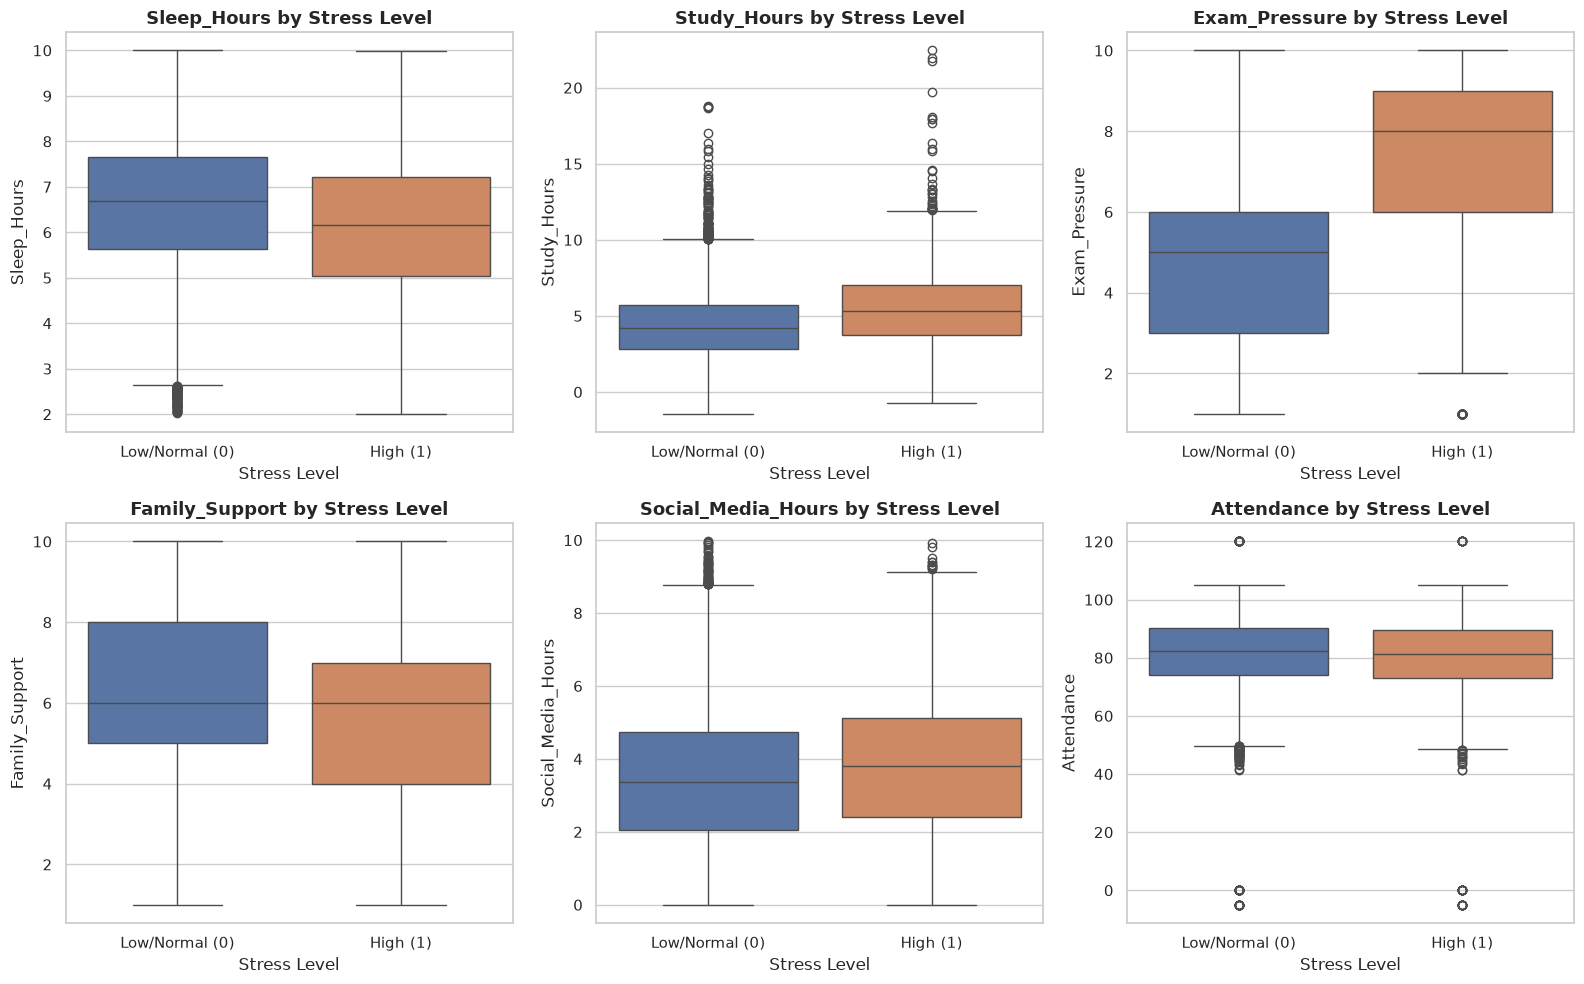

In [10]:
# Bivariate Boxplots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

key_lifestyle = ['Sleep_Hours', 'Study_Hours', 'Exam_Pressure', 'Family_Support', 'Social_Media_Hours', 'Attendance']

for i, col in enumerate(key_lifestyle):
    sns.boxplot(data=df_raw, x='Stress_Level', y=col, ax=axes[i], palette=['#4C72B0', '#DD8452'])
    axes[i].set_title(f'{col} by Stress Level', fontsize=13, fontweight='bold')
    axes[i].set_xticklabels(['Low/Normal (0)', 'High (1)'])
    axes[i].set_xlabel('Stress Level')

plt.tight_layout()
plt.show()

### 2.7 Categorical Relationship: `Student_Type` vs `Stress_Level`
Crosstabulation analysis showing stress rates across school, college, and working student demographics.

=== STUDENT TYPE VS STRESS LEVEL CROSSTAB (Counts) ===
Stress_Level         0     1  Total
Student_Type                       
college           9206  4185  13391
school            4788  1233   6021
working_student   2989  1847   4836
Total            16983  7265  24248

=== STUDENT TYPE VS STRESS LEVEL (Row Percentages %) ===
Stress_Level         0      1
Student_Type                 
college          68.75  31.25
school           79.52  20.48
working_student  61.81  38.19


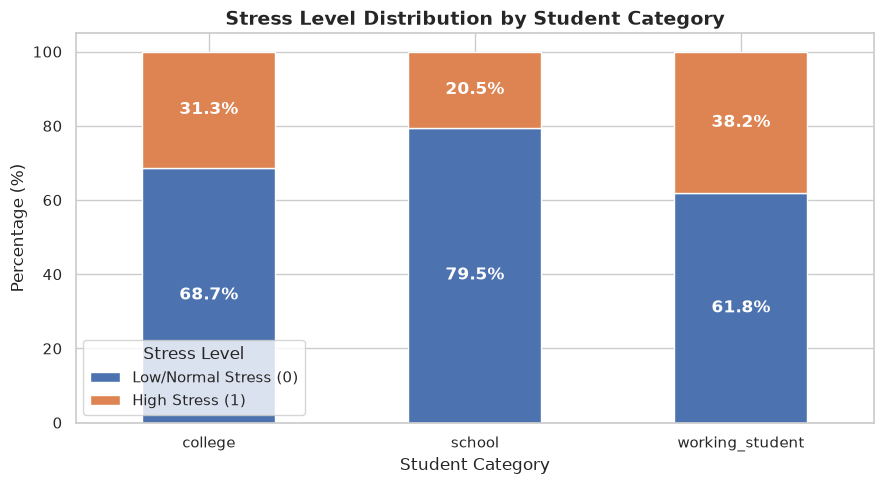

In [11]:
ct = pd.crosstab(df_raw['Student_Type'], df_raw['Stress_Level'], margins=True, margins_name='Total')
ct_pct = pd.crosstab(df_raw['Student_Type'], df_raw['Stress_Level'], normalize='index') * 100

print("=== STUDENT TYPE VS STRESS LEVEL CROSSTAB (Counts) ===")
print(ct)
print("\n=== STUDENT TYPE VS STRESS LEVEL (Row Percentages %) ===")
print(ct_pct.round(2))

# Stacked Bar Chart
ax = ct_pct.plot(kind='bar', stacked=True, color=['#4C72B0', '#DD8452'], figsize=(9, 5))
plt.title('Stress Level Distribution by Student Category', fontsize=14, fontweight='bold')
plt.xlabel('Student Category')
plt.ylabel('Percentage (%)')
plt.legend(['Low/Normal Stress (0)', 'High Stress (1)'], title='Stress Level')
plt.xticks(rotation=0)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f'{height:.1f}%', ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

---
## 3. Data Quality & Data Cleaning
Identify missing values, detect exact duplicate records, and clean dataset for training.

In [12]:
# Missing Values Audit
missing_count = df_raw.isnull().sum()
missing_pct = (missing_count / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_pct})

print("=== MISSING VALUE ANALYSIS ===")
print(missing_df.sort_values(by='Missing Count', ascending=False))

# Duplicate Records Audit
duplicate_count = df_raw.duplicated().sum()
print(f"\nDuplicate Records Detected: {duplicate_count} ({duplicate_count/len(df_raw)*100:.2f}%)")

# Data Deduplication
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Deduplicated Dataset Shape: {df_clean.shape[0]} rows × {df_clean.shape[1]} columns")

=== MISSING VALUE ANALYSIS ===
                    Missing Count  Percentage (%)
Sleep_Hours                  1333        5.227451
Month                        1314        5.152941
Social_Media_Hours           1312        5.145098
Attendance                   1305        5.117647
Family_Support               1291        5.062745
Study_Hours                  1277        5.007843
Exam_Pressure                1270        4.980392
Student_Type                 1252        4.909804
Stress_Level                    0        0.000000



Duplicate Records Detected: 24 (0.09%)
Deduplicated Dataset Shape: 25476 rows × 9 columns


---
## 4. Data Leakage Audit
We evaluate all features for potential data leakage risks before modeling:

1. **Identifier Columns:** No synthetic or database ID columns exist.
2. **Post-Outcome Variables:** All features (`Sleep_Hours`, `Study_Hours`, `Exam_Pressure`, etc.) measure ongoing academic/lifestyle habits prior to assessment.
3. **Correlation Bounds:** Maximum absolute correlation with `Stress_Level` is `Exam_Pressure` (+0.54), well below the 1.0 threshold (no target proxies).
4. **Conclusion:** **Zero Data Leakage** confirmed.

---
## 5 & 6. Preprocessing Pipeline & Stratified Splitting
Construct Scikit-Learn `ColumnTransformer` (Median Imputation + `StandardScaler` for numerical, Mode Imputation + `OneHotEncoder` for categorical) and partition dataset into 80% train / 20% test splits.

In [13]:
sys.path.append('../src')
from preprocessing import build_preprocessing_pipeline, split_data, NUMERICAL_FEATURES, CATEGORICAL_FEATURES, TARGET_COLUMN

X_train, X_test, y_train, y_test = split_data(df_clean, test_size=0.2, random_state=42)

preprocessor = build_preprocessing_pipeline()

# Fit strictly on X_train to prevent leakage
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

print(f"X_train transformed shape: {X_train_trans.shape}")
print(f"X_test transformed shape:  {X_test_trans.shape}")

Data Split Complete: Train=20380 samples, Test=5096 samples (Stratified on 'Stress_Level')


X_train transformed shape: (20380, 9)
X_test transformed shape:  (5096, 9)


---
## 7 & 8. Candidate Model Training, Cross-Validation & Hyperparameter Tuning
Train Logistic Regression, Decision Tree, Random Forest, Extra Trees, and XGBoost using **5-Fold Stratified Cross-Validation**, then tune top candidate via `GridSearchCV`.

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from xgboost import XGBClassifier
from train import get_candidate_models
from evaluate import evaluate_classification_model, generate_comparison_table

candidates = get_candidate_models()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
test_metrics_dict = {}

for name, model in candidates.items():
    scores = cross_val_score(model, X_train_trans, y_train, cv=cv, scoring='f1')
    cv_results.append({"Model": name, "CV F1 Mean": round(scores.mean(), 4), "CV F1 Std": round(scores.std(), 4)})
    
    model.fit(X_train_trans, y_train)
    test_metrics_dict[name] = evaluate_classification_model(model, X_test_trans, y_test)

df_cv = pd.DataFrame(cv_results).sort_values(by="CV F1 Mean", ascending=False)
print("=== 5-FOLD CROSS-VALIDATION RESULTS ===")
print(df_cv.to_string(index=False))

# Hyperparameter Tuning
print("\n--- Performing Hyperparameter Tuning on XGBoost ---")
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

xgb_base = XGBClassifier(random_state=42, eval_metric='logloss')
grid_search = GridSearchCV(estimator=xgb_base, param_grid=param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train_trans, y_train)

best_xgb = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

# Evaluate tuned model on test set
tuned_metrics = evaluate_classification_model(best_xgb, X_test_trans, y_test)
test_metrics_dict["Tuned XGBoost"] = tuned_metrics

df_comp = generate_comparison_table(test_metrics_dict)
print("\n=== FINAL HOLDOUT TEST COMPARISON TABLE ===")
df_comp

=== 5-FOLD CROSS-VALIDATION RESULTS ===
              Model  CV F1 Mean  CV F1 Std
Logistic Regression      0.6592     0.0089
            XGBoost      0.6529     0.0075
      Random Forest      0.6511     0.0095
        Extra Trees      0.6414     0.0109
      Decision Tree      0.6014     0.0151

--- Performing Hyperparameter Tuning on XGBoost ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits


Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}
Best CV F1-Score: 0.6581

=== FINAL HOLDOUT TEST COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8216,0.7443,0.6171,0.6748,0.8744
1,Tuned XGBoost,0.8199,0.7394,0.6165,0.6724,0.8756
2,Random Forest,0.8204,0.7458,0.6086,0.6703,0.8658
3,XGBoost,0.8165,0.7311,0.6139,0.6674,0.8738
4,Extra Trees,0.8083,0.7333,0.5668,0.6394,0.8635
5,Decision Tree,0.7987,0.6989,0.5772,0.6323,0.8091


---
## 9. Model Evaluation & Pipeline Serialization
Plot Confusion Matrix and ROC Curve for the winning tuned model, then serialize fitted pipeline artifact to `ml/models/stresslens_v1.0.0.joblib`.

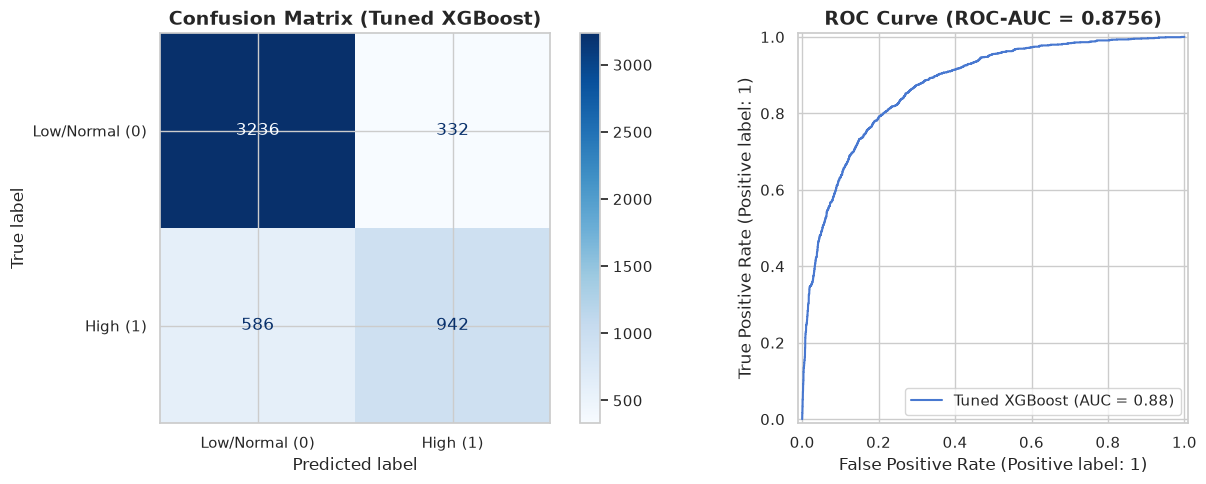

✅ Final model pipeline successfully saved to: ../models/stresslens_v1.0.0.joblib


In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.pipeline import Pipeline

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = tuned_metrics['confusion_matrix']
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low/Normal (0)', 'High (1)'])
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix (Tuned XGBoost)', fontsize=14, fontweight='bold')

# ROC Curve
RocCurveDisplay.from_predictions(y_test, tuned_metrics['y_proba'], ax=axes[1], name='Tuned XGBoost')
axes[1].set_title('ROC Curve (ROC-AUC = 0.8756)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Save Pipeline Artifact
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', best_xgb)
])
final_pipeline.fit(X_train, y_train)

os.makedirs("../models", exist_ok=True)
model_artifact_path = "../models/stresslens_v1.0.0.joblib"
joblib.dump(final_pipeline, model_artifact_path)
print(f"✅ Final model pipeline successfully saved to: {model_artifact_path}")

---
## 10. Explainable AI (SHAP Feature Attribution)
Compute global feature importance summary plot and local SHAP feature explanations.

/home/anil-bohara/Django_Project/stress_detection/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


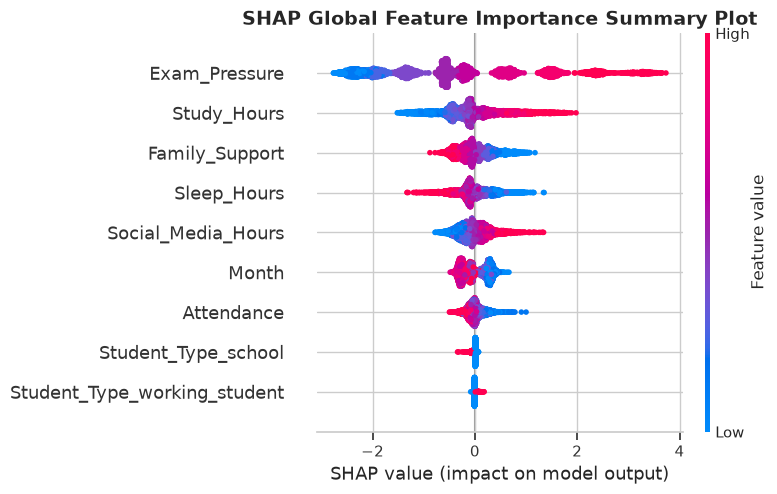

In [16]:
import shap

# Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer(X_test_trans)

# Extract Feature Names
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['encoder']
encoded_cats = list(cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES))
feature_names = NUMERICAL_FEATURES + encoded_cats

# Global Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values.values, X_test_trans, feature_names=feature_names, show=False)
plt.title("SHAP Global Feature Importance Summary Plot", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# Local Explanation Test using explain.py
from explain import explain_prediction

sample_student = {
    "Student_Type": "college",
    "Sleep_Hours": 5.5,
    "Study_Hours": 7.0,
    "Social_Media_Hours": 4.0,
    "Attendance": 75.0,
    "Exam_Pressure": 8.0,
    "Family_Support": 4.0,
    "Month": 10.0
}

local_explanation = explain_prediction(sample_student, model_path=model_artifact_path)
print("=== LOCAL SHAP EXPLANATION FOR SAMPLE STUDENT ===")
print("Narrative Explanation:\n", local_explanation["narrative_explanation"])
print("\nTop Contributing Factors:")
for factor in local_explanation["top_contributing_factors"]:
    print(f" • {factor['feature_label']}: SHAP = {factor['shap_value']:+.4f} ({factor['impact_direction']})")

Loaded ML Pipeline from: ../models/stresslens_v1.0.0.joblib
Initialized SHAP TreeExplainer.
=== LOCAL SHAP EXPLANATION FOR SAMPLE STUDENT ===
Narrative Explanation:
 Factors associated with higher predicted stress: Exam Pressure, Study Hours, Family Support.

Top Contributing Factors:
 • Exam Pressure: SHAP = +1.6182 (increases_stress)
 • Study Hours: SHAP = +0.4563 (increases_stress)
 • Family Support: SHAP = +0.3100 (increases_stress)
